
# **Lecture 4. Linear Classification and Generalization**


# **4.1. Objectives**

At the end of this lecture, you will be able to understand:

- **Optimization** view of learning

- apply optimization algorithms such as **gradient descent, stochastic gradient descent, and quadratic program**.



We talked about **how to formulate maximum margin linear classification as an optimization problem ?** 

Here, We're going to try to **understand the solutions to that optimization problem** and 

* **how to find those solutions** . 

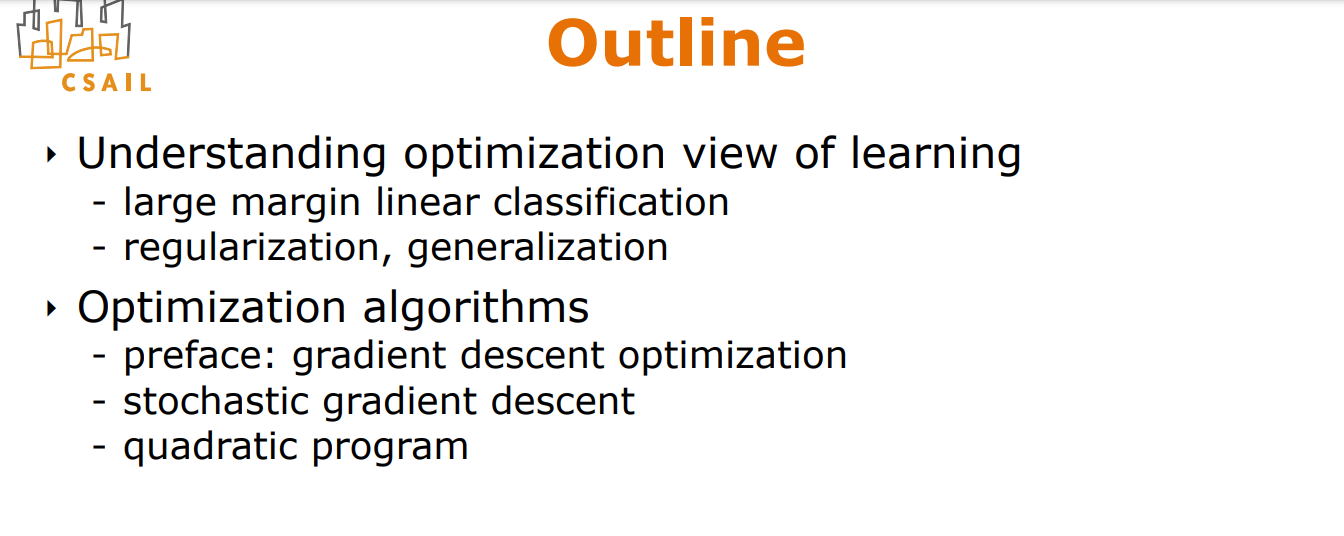



# **4.2. Review and the Lambda parameter**

The objective function to minimise is still

**$J(\theta , \theta_0) = \frac{1}{n} \sum_{i=1}^{n} \text{Loss}_h (y^{(i)} * (\theta \cdot x^{(i)} + \theta_0 )) + \frac{\lambda }{2} \mid \mid \theta \mid \mid ^2$**




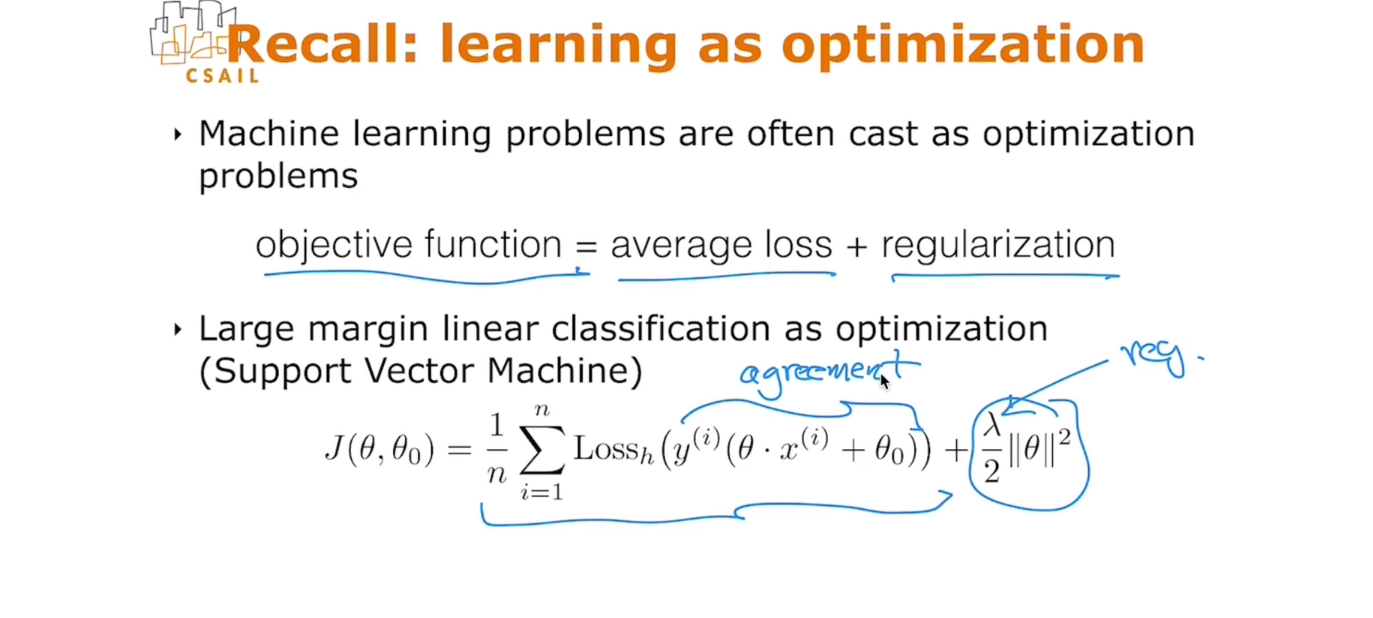

Where the **first** term is the **average loss** and the **second** one is the **regularisation**.

* The **average loss** is what we are trying to **minimize**.

* Minimizing the regularization term will try instead to push the margin boundaries further and further apart.

* And the balance between these two are controlled by the **regularization** **parameter** **lambda**.

* **Minimising** the **regularisation** term $\frac{\lambda }{2} \mid \mid \theta \mid \mid ^2$ 

 * We **maximise the distance of the margin boundary** $\frac{1}{\mid \mid \theta \mid \mid}$.


When the agreement here falls below value one, agreement between the linear function and the provided label, when that falls below one, we start incurring loss.



And as we do that, we start hitting the actual training examples.
The boundary needs to orient itself, and we may start incurring losses.


## **The role of the lambda parameter**

As we change the regularization parameter, lambda, we change the balance between these two terms.

* The **larger the value lambda** is, the **more we try to push the margin boundaries apart**;

* The **smaller** it is, the more **emphasis we put on minimizing the average laws on the training example**, reducing the distance of the margin boundaries  up to the extreme $\lambda=0$ where the margin boundaries themselves collapse towards the actual decision boundary.

The further and further the margin boundaries are posed, the more the solution will be guided by the bulk of the points, rather than just the points that are right close to the decision boundary.
So the solution changes as we change the regularization parameter.

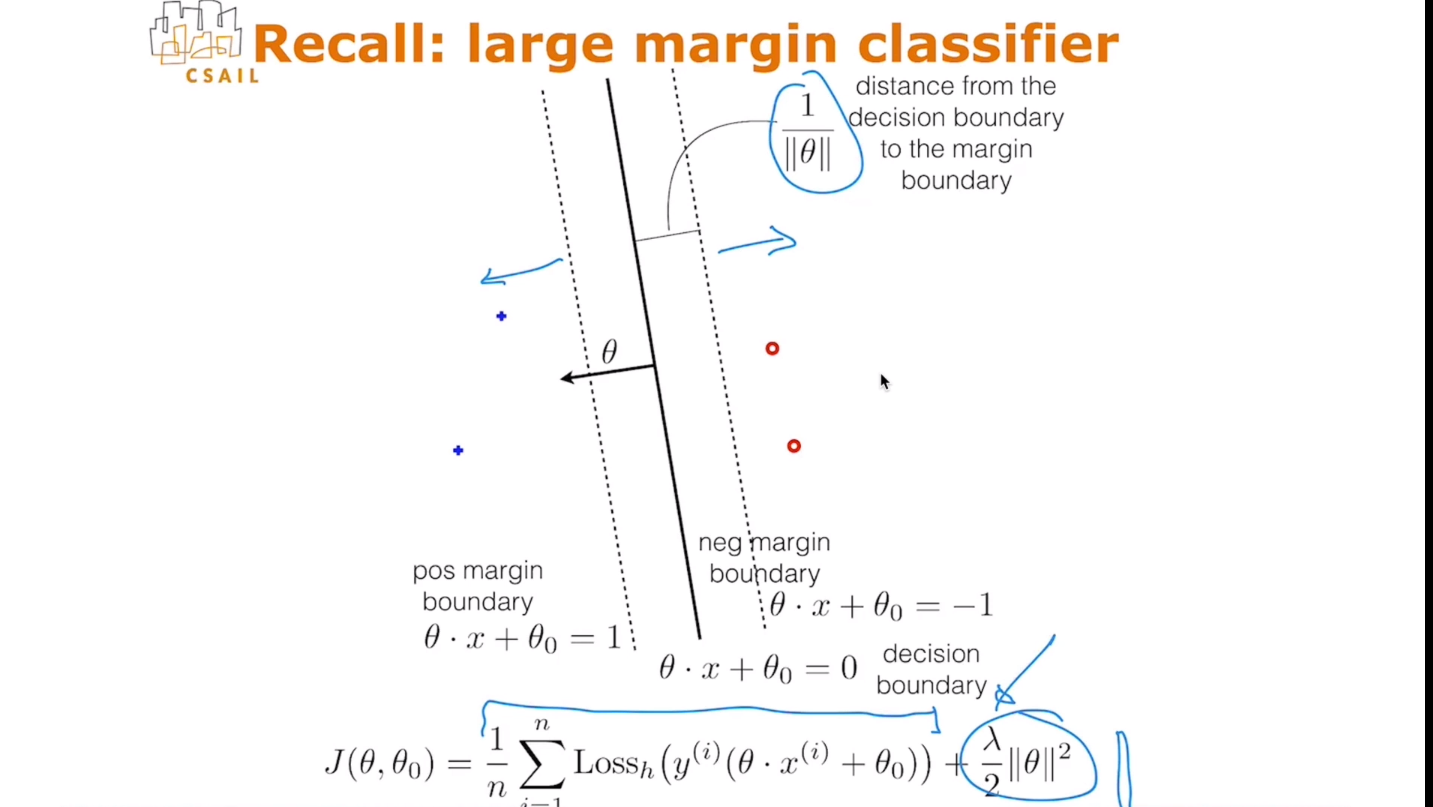

### **`Example 1 Linearly Separable`** 

And I start with the regularization parameter being small, 0.1.

* So I'm emphasizing correct classification of these examples.

* And the solution that I get is then that all the **examples are on the correct side of the decision boundary**.

* For example, this one here is on the correct side
of the positive margin boundary.

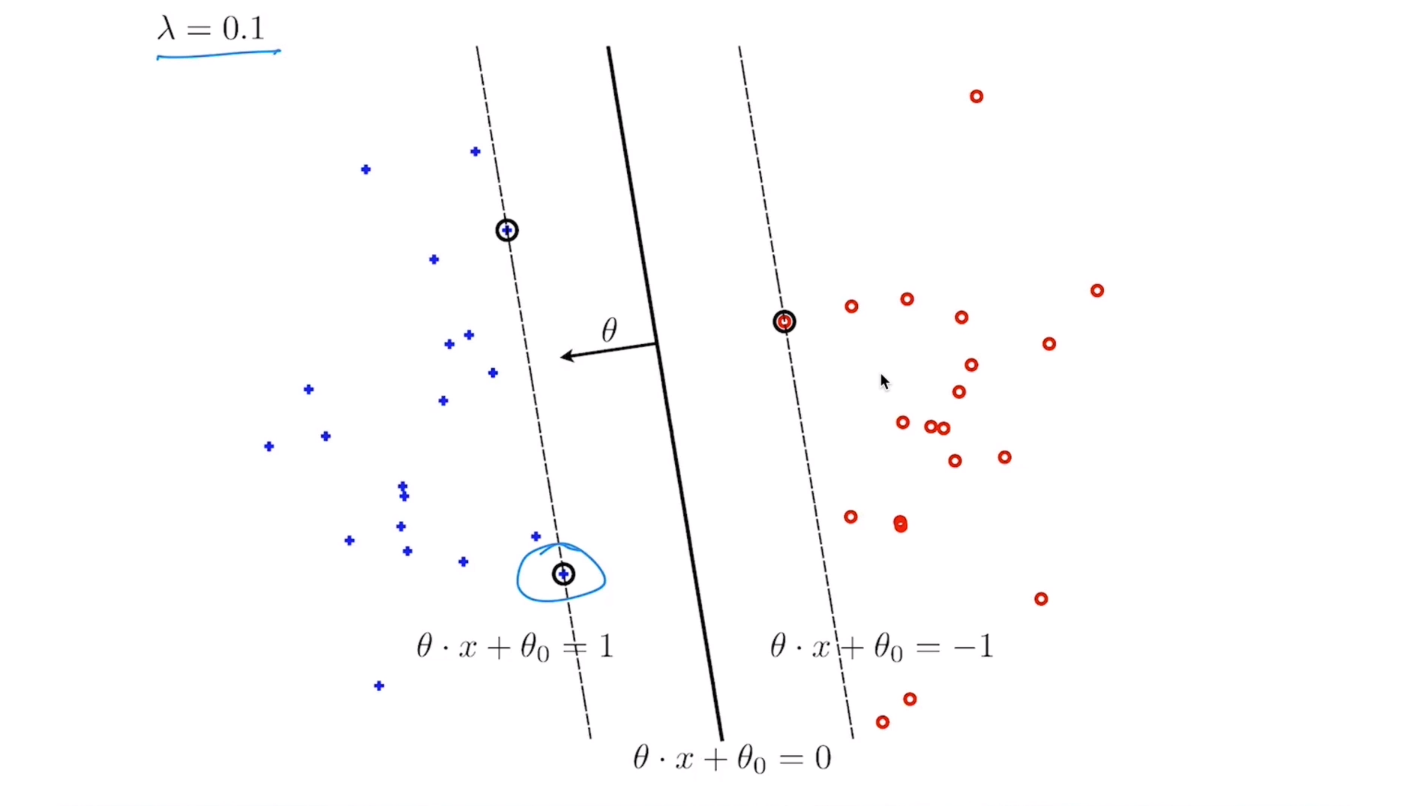

As I start **increasing the value of lambda**, I put **more emphasis on regularization term**, that is, **trying to push the margin boundaries further and further apart**.

* In this case, they did not yet move because that additional emphasis on the regularization term is not enough to counterbalance losses that I would incur if the margin boundaries past the actual examples.

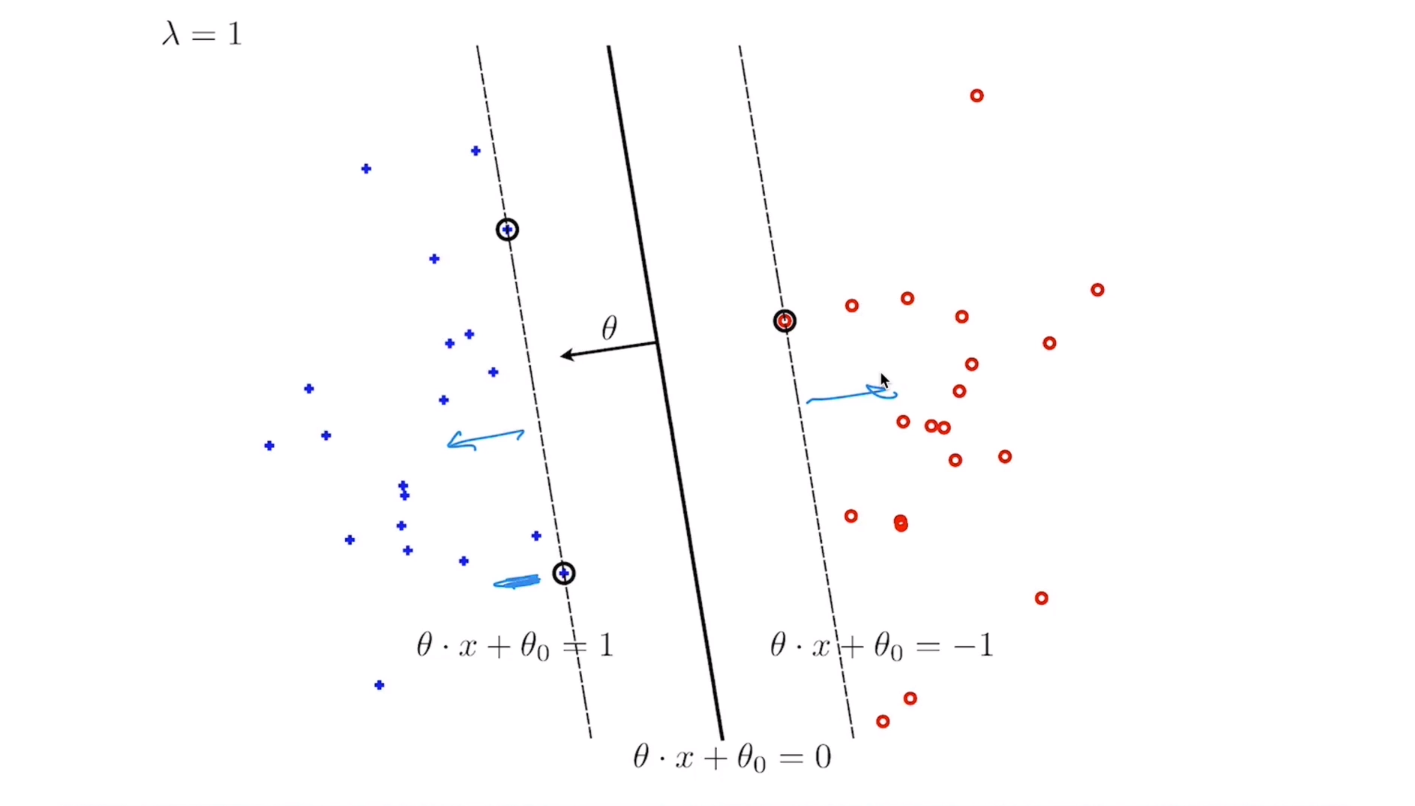

As I **increase that further,** the solution changes.

* As I **increase their value of lambda further**, I **start allowing some of the margin boundaries to let the examples within the actual margin boundaries.**

* And as you can see, the further and further the margin boundaries are posed, the **more the solution will be guided by the path of the points**, **rather than just the points that are right close to the decision boundary**.

* So the solution changes as we change the regularization
parameter.

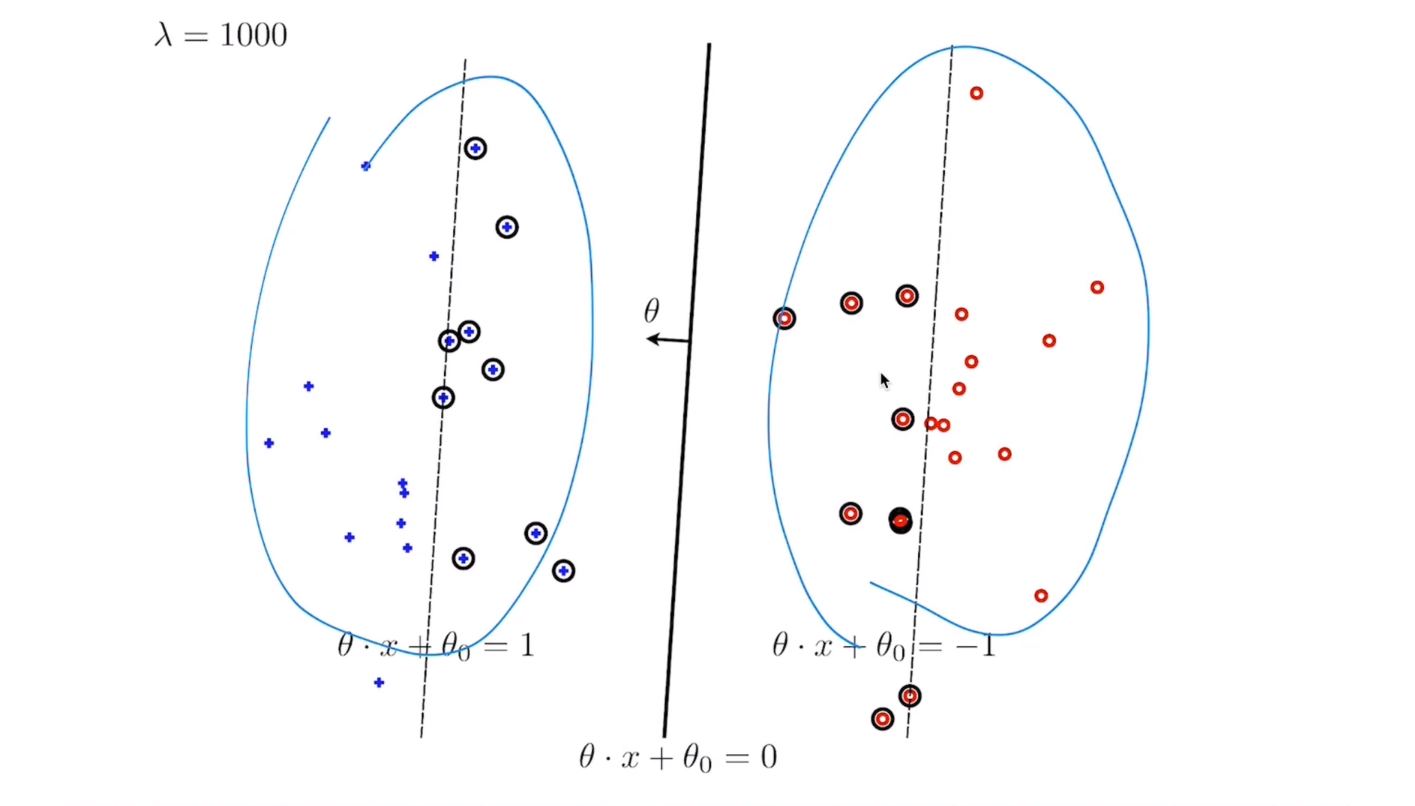


In other terms:

- **$\lambda = 0$ :** 
if we consider a **minimisation of only the loss function**, without the margin boundaries, (admitting a separable problem) we would have infinite solutions within the right classifiers (similarly to the perceptron algorithm);


- **$\lambda = ϵ^+$ :** 
With a **very small (but positive)** $\lambda$, t**he margin boundaries would be immediately pushed to the first point**(s) at the minimal distance to the classifier (aka the "support vectors", from which the name of this learning method), and only this point(s) would drive the "optimal" classifier within all the possible ones (we overfit relatively to these boundary points);


- **$\lambda = \text{large}^+$ :**
As we **increase $\lambda$**, we are starting to give weight also to the points that are further apart, and the optimal classifier may be changing as a consequence, eventually even misclassifying some of the closest points, if there are enough far points pushing for such classifier.


### **`Example 2 Linearly Not Separable`** 

The problem is actually already **not linearly separable**.

* And I have a **small value of the regulators** and parameter.

* But I **cannot find a separable solution**, so some of the margin constraints are violated.

So I will **incur losses on some of those points** already here.



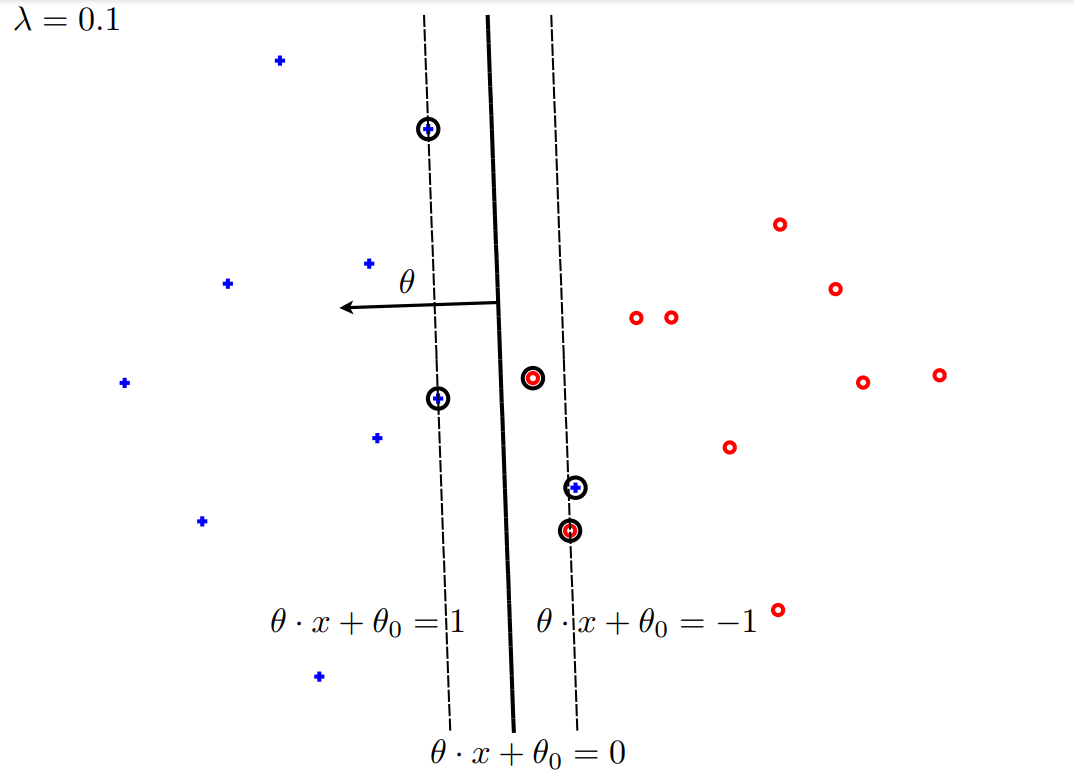

As I **start increasing the value of the regularization parameter**
lambda, 

* the solution starts changing as before, being guided more by where the bulk of the points are similar to before.

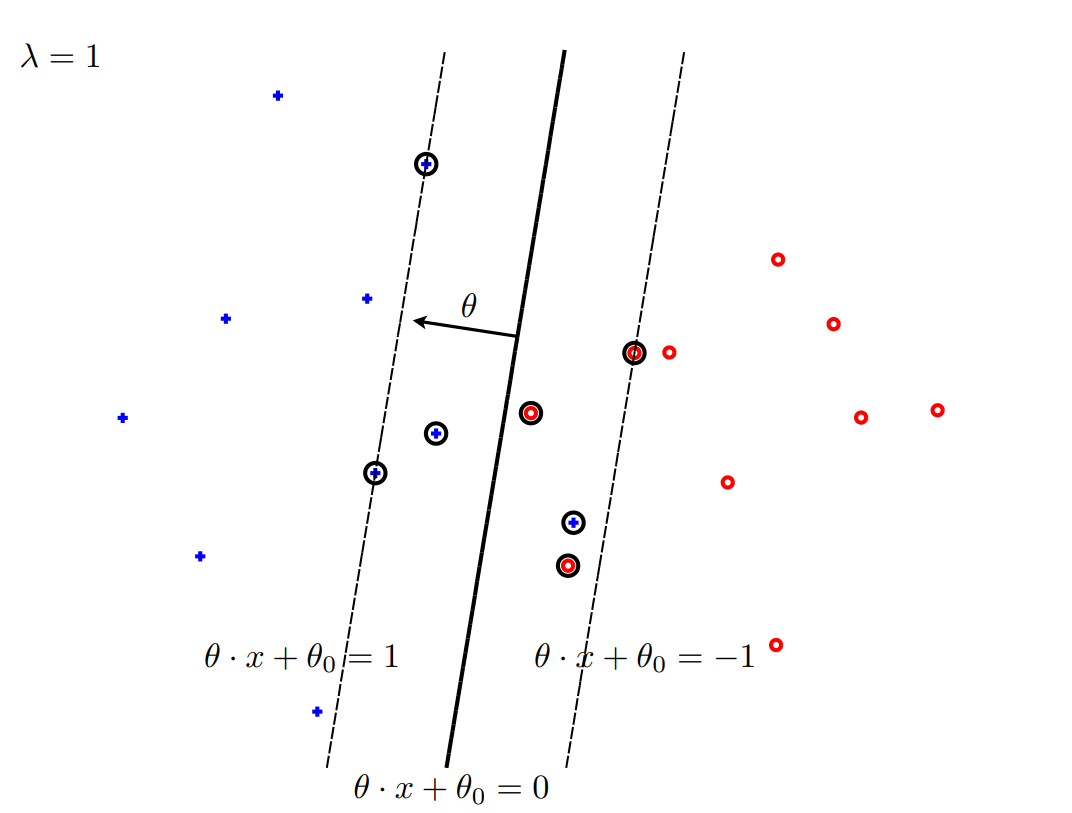

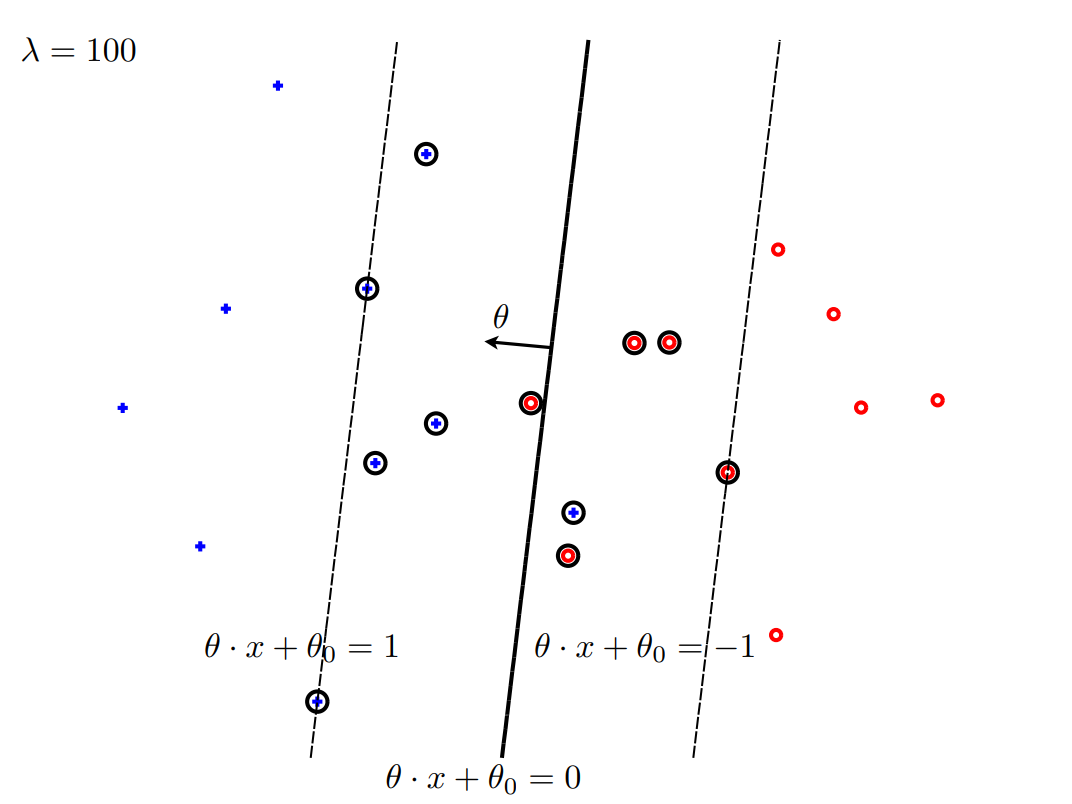

## **Que 1 : Distance from a line to a point in terms of components**


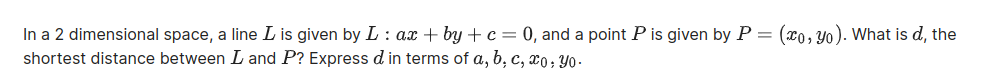

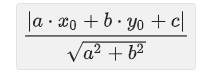

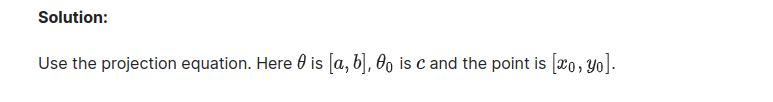

## **Que 2 : Varying Lambda in the Geometric Sense**


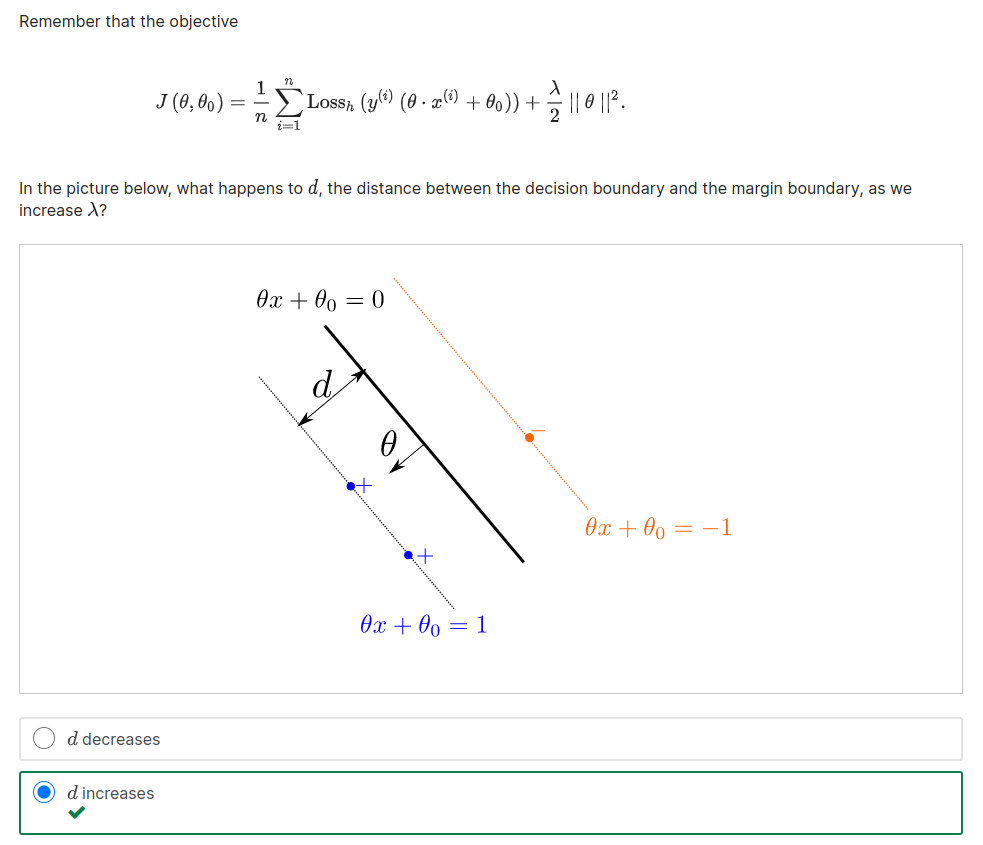

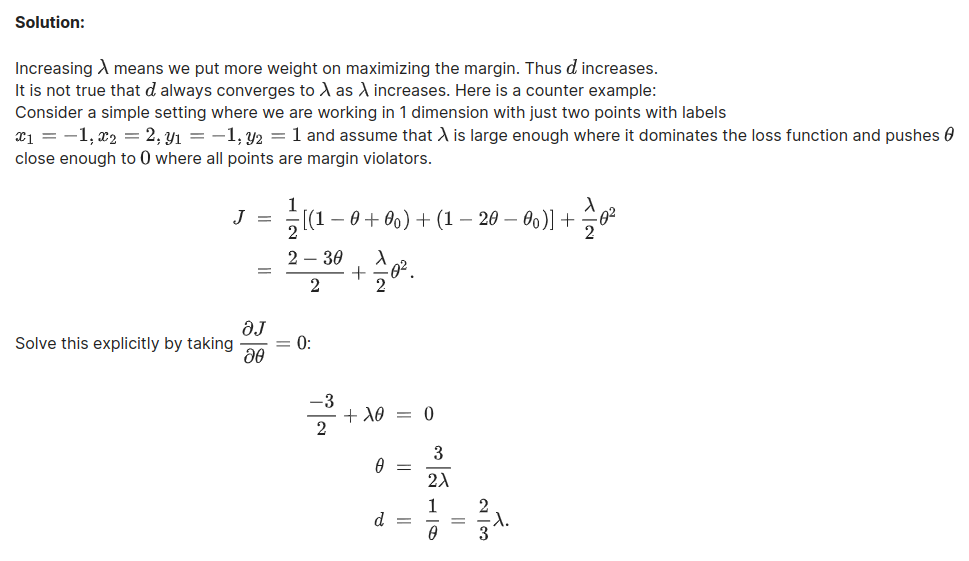


# **4.3. Regularization and Generalization**




We minimise a new function $J/\lambda = \frac{1}{\lambda} * \frac{1}{n} \sum_{i=1}^{n} \text{Loss}_h (\cdot) + \frac{1 }{2} \mid \mid \theta \mid \mid ^2$ (as $\lambda$ is positive minimising the new function is equal to minimising the old one).

We can think the objective function as **function of the $\frac{1}{\lambda}$ ratio (that we denote as "c"):**

- $1/\lambda$ small -> wide margins, high losses
- $1/\lambda$ big   -> narrow margins, small/zero losses

* So as $c$ is large, we emphasize losses.

* As **$c$ is small**, we emphasize **simpler solutions that have a large margin**.

* As **$c$ is large**, we are looking for c**omplex solution that fits their training examples better**.

### **Training Loss**

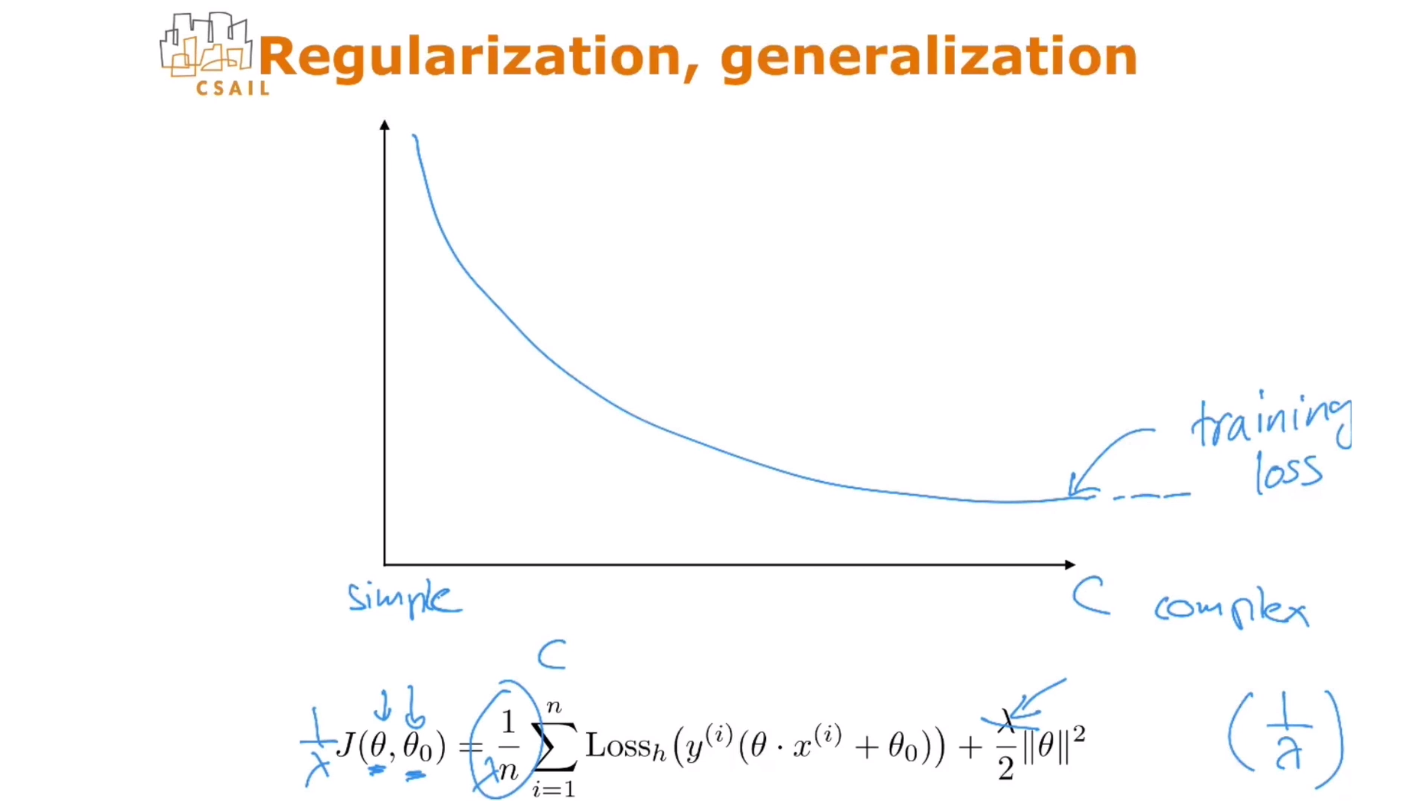


Such function, once minimised, will result in optimal classifiers $h(\theta^* , \theta_0^* , c )$ from which I can **compute the average loss**. 

* Such **average loss would be a convex**, **monotonically decreasing function of $c$**, although it would not reach zero losses even for very large values of $c$ if the problem is not linearly separable.

* **`Note :`** And as a result, I couldn't achieve a **$0$ average loss**.

### **Test Loss**


If we could measure also the **test loss** (from the test set) obtained from such optimal classifiers, we would find a **typical u-shape where test loss first decreases with $c$**, but then would **growth up again**. 

 * Also, the **test loss (or "error") would be always higher than the training loss**, as we are fitting from the training set, not the test set.

 * We call **$c^* ~$ the "optimal" $c$ value that minimise the test error**. If we could find it, we would have found the value of $\lambda$ that best generalise the method.

Now, we cannot do that, but we will talk about how to approximately do that.


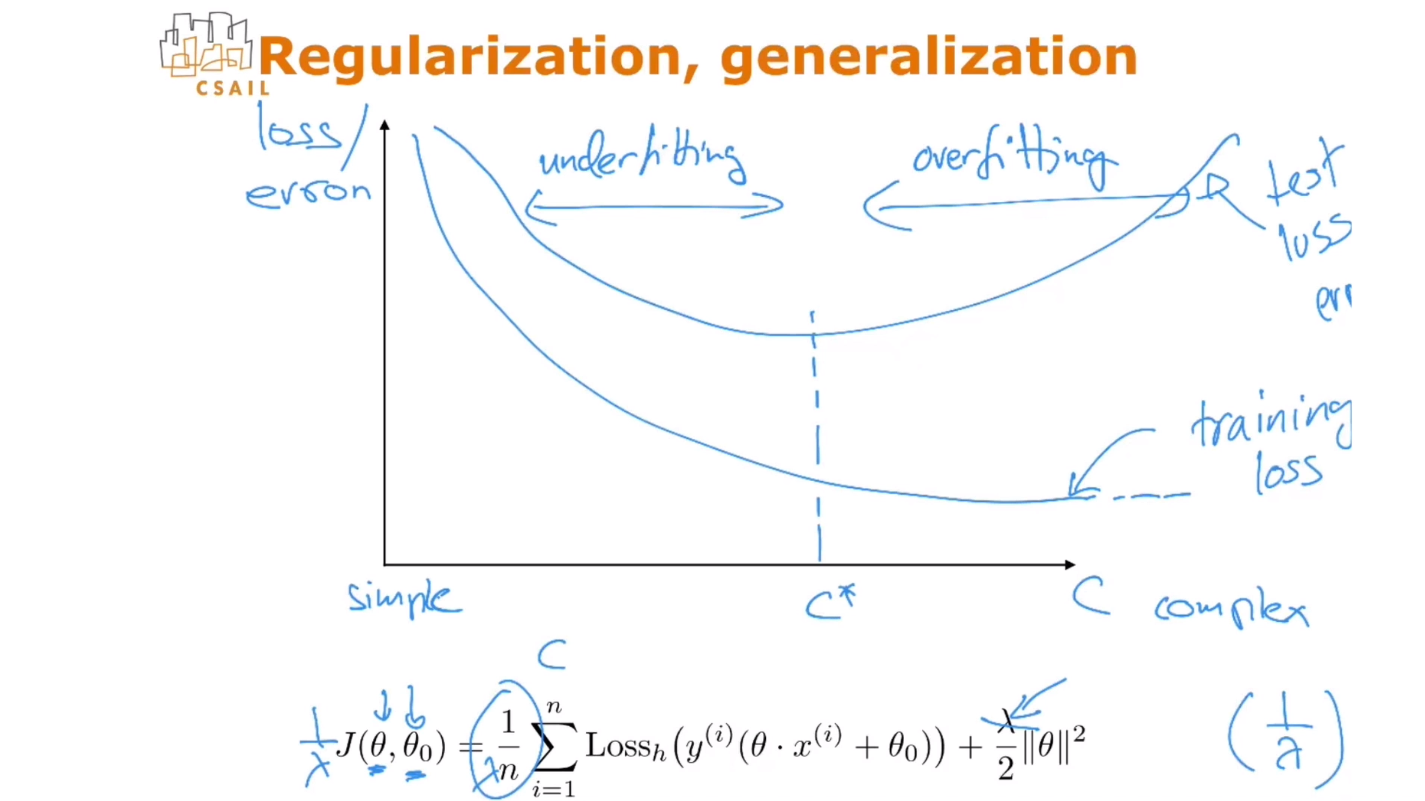


* With **$c$ below $c^* ~$ if I am underfitting :** if I make the method more complex, i.e., I increase the value of c, I will actually **improve my test performance**.

* with **$c$ above $c^* ~$ I am overfitting :** (around the point(s) closest to the decision margin) :  then making the method even more complex will result in a **poorer test loss or error**. So I will do **less well as a resul**t.





* How to find $c^* ~$? 
 
 * By dividing my training set in a "new" **training set**, and a (smaller) **validation set**, our new "pretending" test set.

 * Using this "new" training set we can find the optimal classifier as function of $c$, and at that point use $h(\theta^* , \theta_0^* , c )$ to evaluate the **validation loss** (or "validation error") to numerically find an approximate value of $c^* ~$.

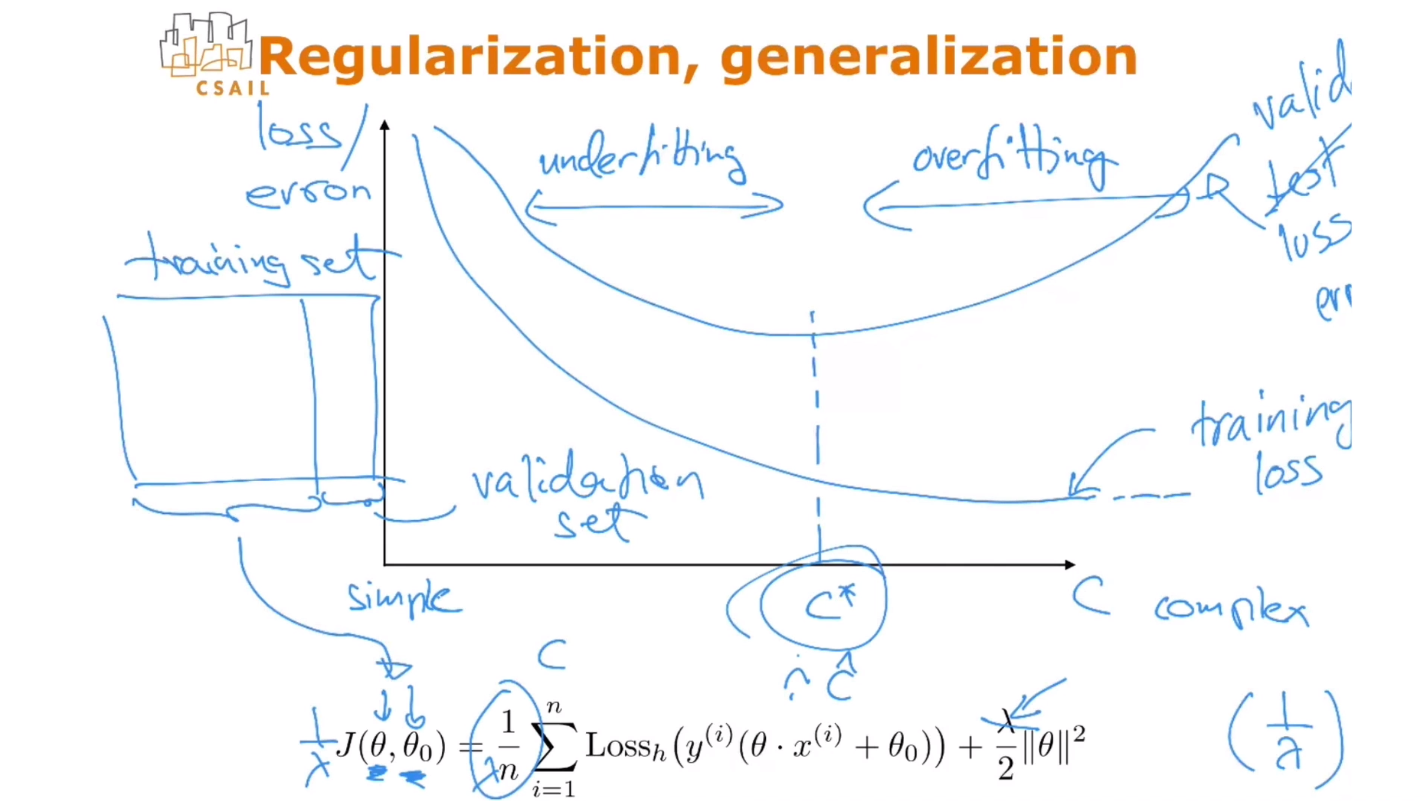

## **Generalization 1**


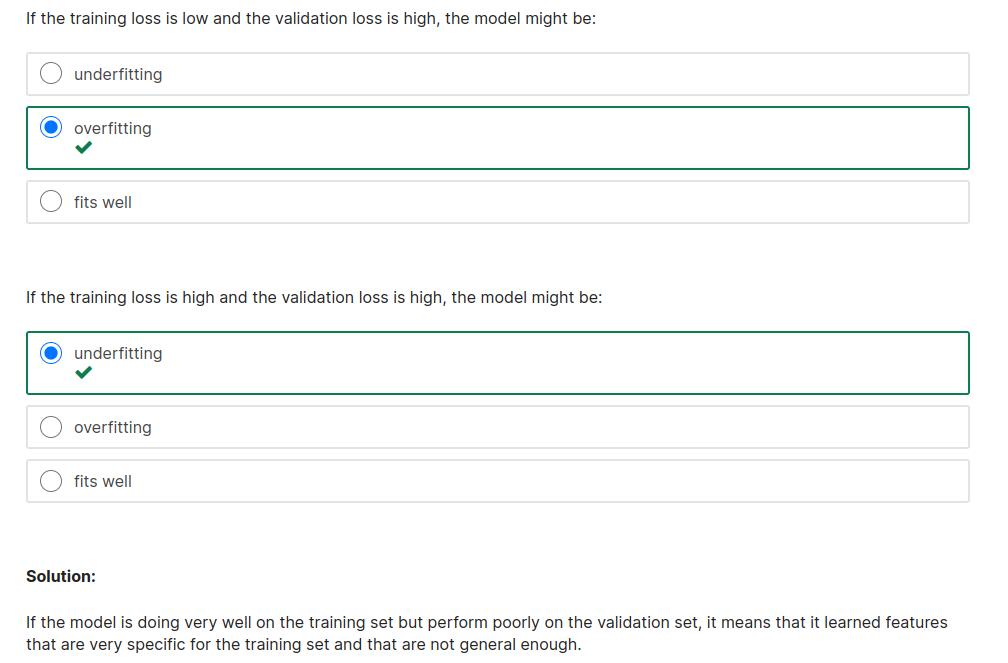

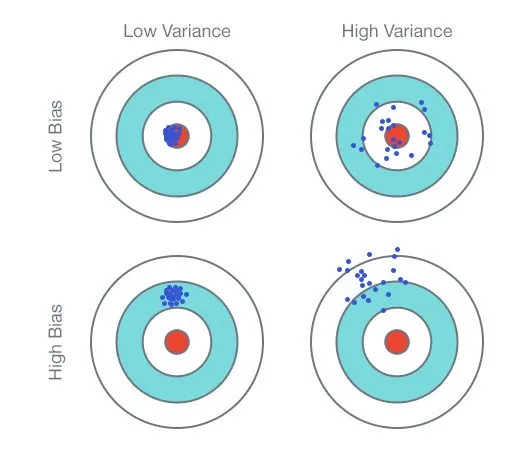

## **Training set and Test Set**

**`Training set :` targets/labels are available for all data points**

**`Test set :` targets/labels are not available**

Sometimes we split training set into two,
 - the new training set which we use to build our classifier/model,
 
 - and the validation set on which we test our classifier
all this happens before the classifier even sees the test set

Why we do this: **we want to ensure that our classifier is good before it even meets the test set**

examples
- dividing the training set 80:20, where 80% of points are used for training and 20% for validation
- when we have a small dataset, say only n points we can use leave one out method, where we use n-1 points for training and one point for validation and cycle through this n times (so that each point has acted as a validation point once) and report the average validation error

### **`Summary`** 

 So far we have seen how to **qualitatively** understand the **type of solutions that we get when we vary the regularization parameter and optimize with respect to $\theta$ and $\theta_0$**.

# **Optimization Algorithms**


# **4.4. Gradient Descent**

* Now, algorithms for finding those solutions. 

 * when we vary the regularization parameter and optimize w.r.t $\theta$ and $\theta_0$.


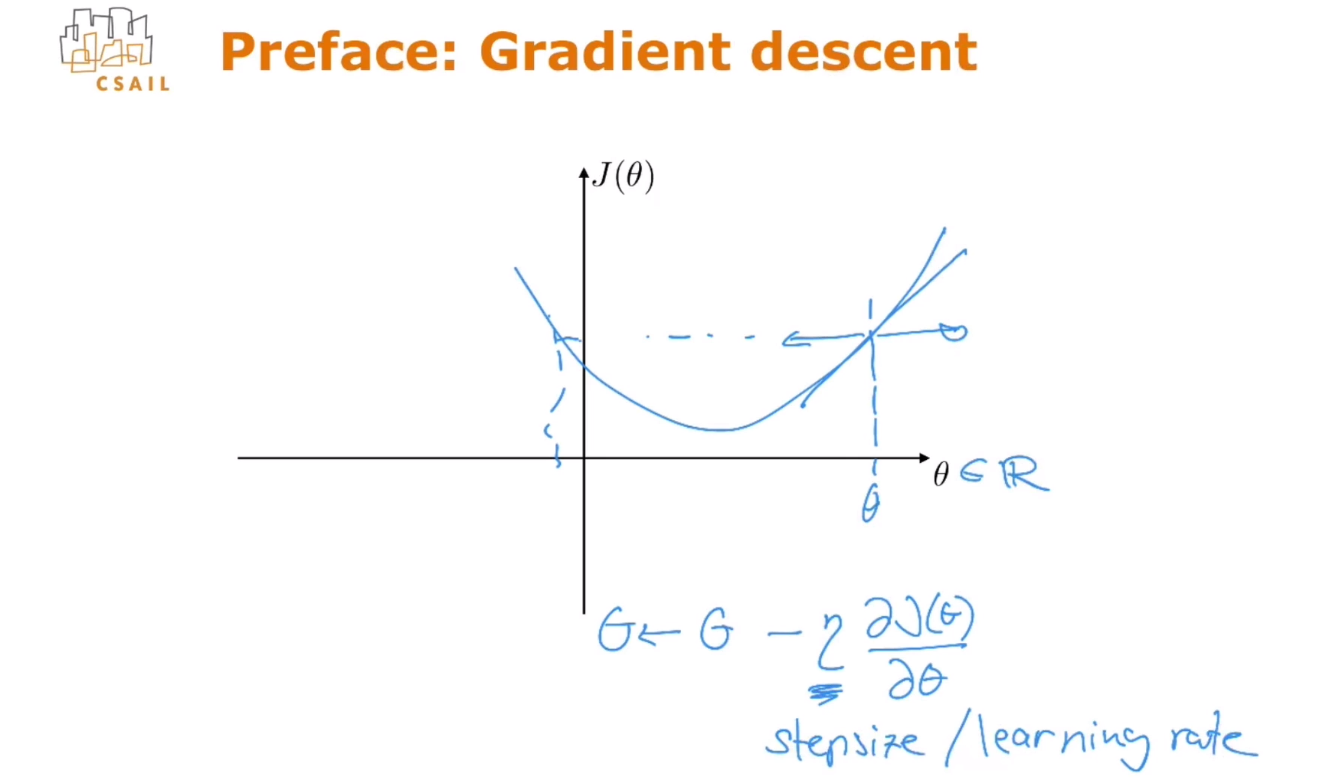

**Gradient descent algorithm** to find the minimum of a function $J(\theta)$ with respect to a parameter $\theta \in \mathbb{R}$ (for simplicity).

- I start with a given $\theta_{\text{start}}$

- I evaluate the derivative $\partial{J}/\partial{\theta}$ at $\theta_{\text{start}}$, i.e. the slope of the function in $\theta_{\text{start}}$. 
 * If this is positive, increasing $\theta$ will increase the $J$ function and the opposite if it is negative . 
 
 * In both cases, if I move $\theta$ in the opposite direction of the slope, I move toward a lower value of the function.

- My new, updated value of $\theta$ is then $\theta = \theta - \eta \frac{\partial{J}}{\partial{\theta}}$ where $\eta$ is known as the **step size** or **learning rate**, and the whole equation as **gradient descent update rule**.
- We stop when the variation in $\theta$ goes below a certain threshold.

#### **Learning rate/ Step Size**


If **$\eta$ is too small:** we may converge very slowly or end up trapped in small local minima;

If **$\eta$ is too small :** we may diverge instead of converge to the minimum (going to the opposite direction respect to the minimum).

If the **function is strictly convex**, then there would be a constant learning rate small enough that I am guaranteed **quickly to get to the minimum of that function**.


## **Multi-dimensional case**

The multi-dimensional case is similar, we update each parameter with respect to the corresponding partial derivative (i.e. the corresponding entry in the gradient):

 $\theta_j = \theta_j - \eta   \frac{\partial{J}}{\partial{\theta_j}}$ or, in vector form,
 $\mathbf{\theta} = \mathbf{\theta} - \eta \nabla{J(\mathbf{\theta})}$

 (where $\nabla{J(\mathbf{\theta_j})}$ is the gradient of $J$, i.e. the column vector concatenating the partial derivatives with respect to the various parameters)


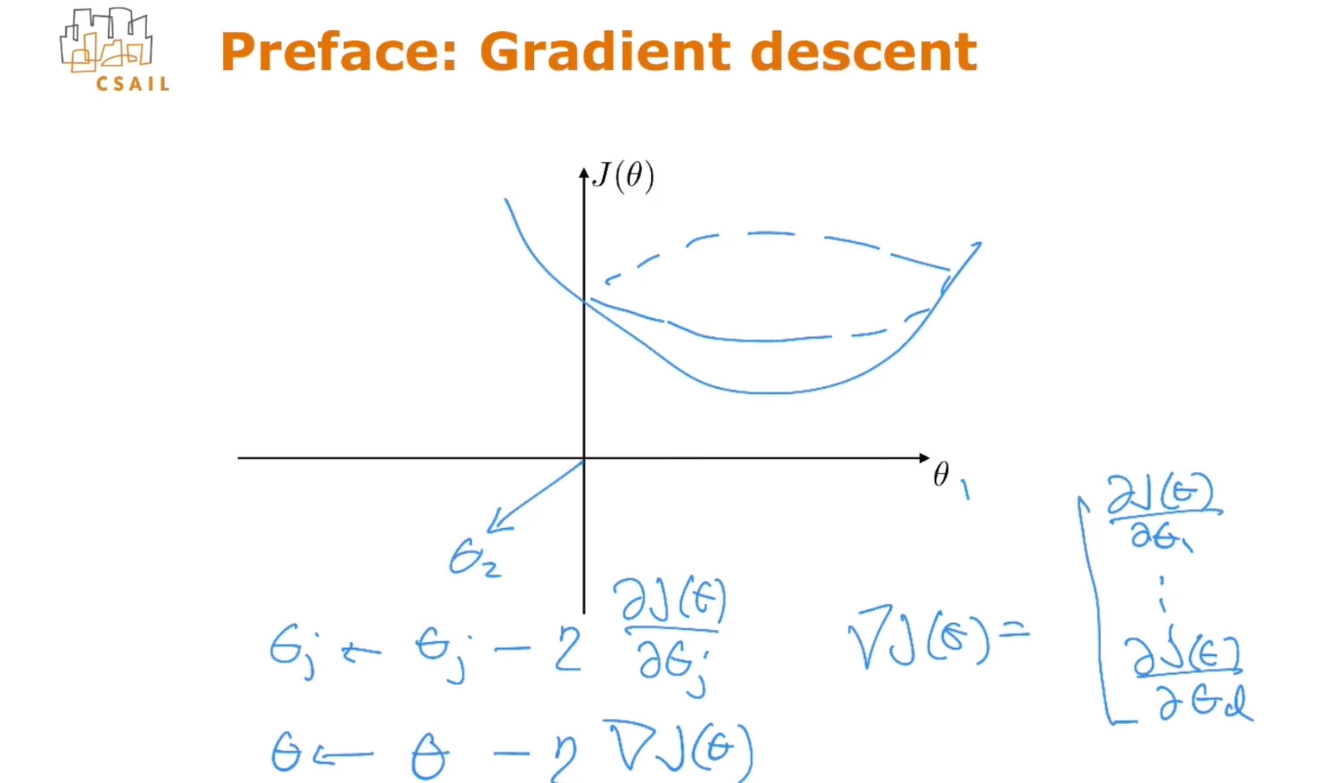

## **Gradient Descent: Geometrically Revisited**


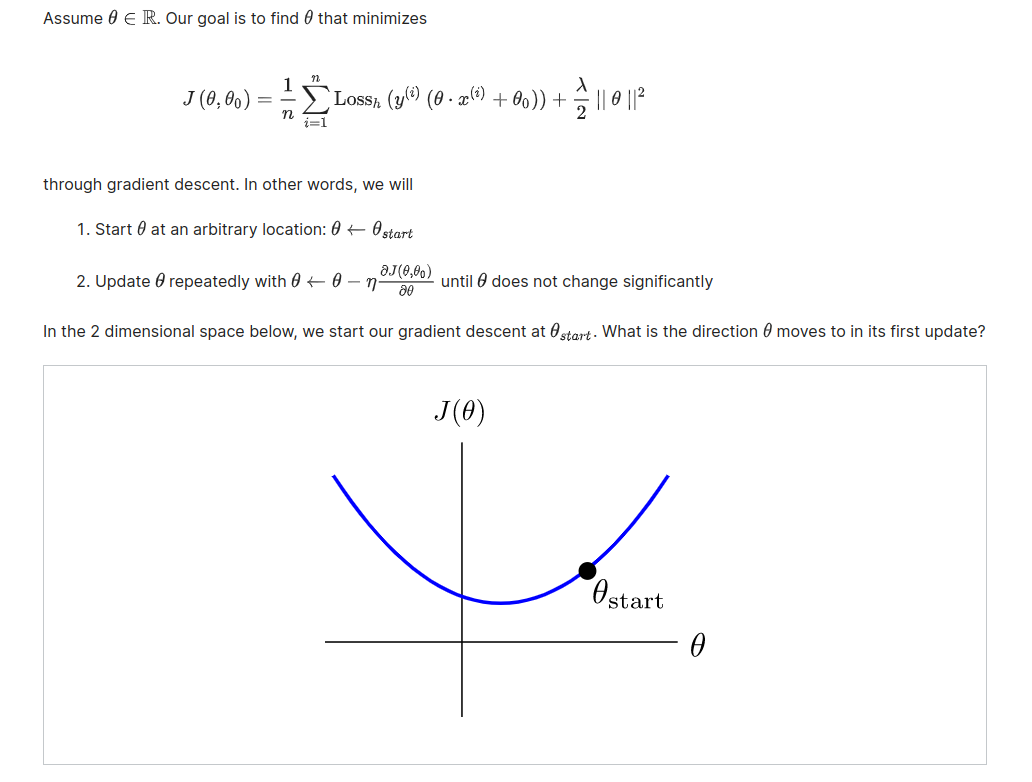

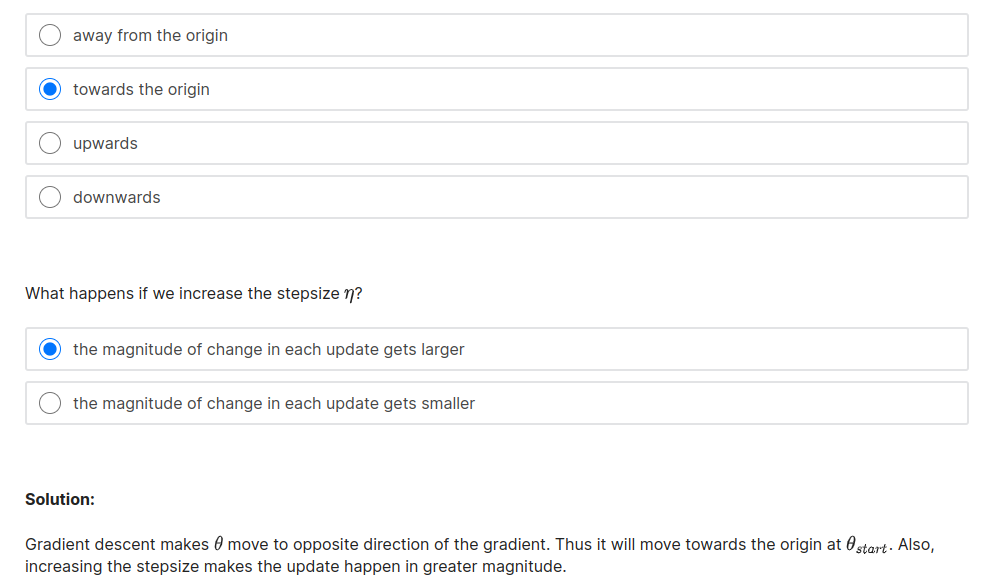

# **4.5. Stochastic Gradient Descent**

Let first note that we can write 
\begin{align}
\frac{1}{n} \sum_{i=1}^n (a_i) +b \quad as \quad  \frac{1}{n} \sum_{i=1}^n (a_i +b)
 \end{align}

Our original objective function can hence be written as

\begin{align}
        J(\theta , \theta_0) = \frac{1}{n} \sum_{i=1}^{n} \left[ \text{Loss}_h (y^{(i)} * (\theta \cdot x^{(i)} + \theta_0 )) + \frac{\lambda }{2} \mid \mid \theta \mid \mid ^2 \right]
    \end{align}
    

Let's also, for now, simplify the calculation omitting the offset parameter:

\begin{align}
J(\theta) = \frac{1}{n} \sum_{i=1}^{n} \left[ \text{Loss}_h (y^{(i)} * (\theta \cdot x^{(i)} )) + \frac{\lambda }{2} \mid \mid \theta \mid \mid ^2 \right]
\end{align}




We can now see the above objective function as an _expectation_ of the function

\begin{align}
 J(\theta): E[J(\theta)] = \frac{1}{n} \sum_{i=1}^{n} J[\theta]
\end{align}

 where t

We can then use a stochastic approach (SGD, standing for **Stochastic Gradient Descen**), 

* where we sample at random from the training set a single data pair $i$, 

* we compute the gradient of the objective function with respect to that single parameter $\frac{\partial J_i(\theta)}{\partial \theta}$, 

* we compute an update of $\theta$ following the same rule as before ($\mathbf{\theta} = \mathbf{\theta} - \eta_t \nabla{J_i(\mathbf{\theta})}$), 

* we sample an other data pair $j$, 

* we re-compute the gradient with respect to this new pair,

*  we update again ($\mathbf{\theta} = \mathbf{\theta} - \eta_t \nabla{J_j(\mathbf{\theta})}$), and so on.

This has the advantage to be more efficient than taking all the data, compute the objective function and the gradients with respect to all the data points (could be milions!), and perform the gradient descent with respect to such function.

By sampling we introduce however some stochasticity and noises, and hence we need to put care on the learning parameter that need to be reduced to avoid to diverge.


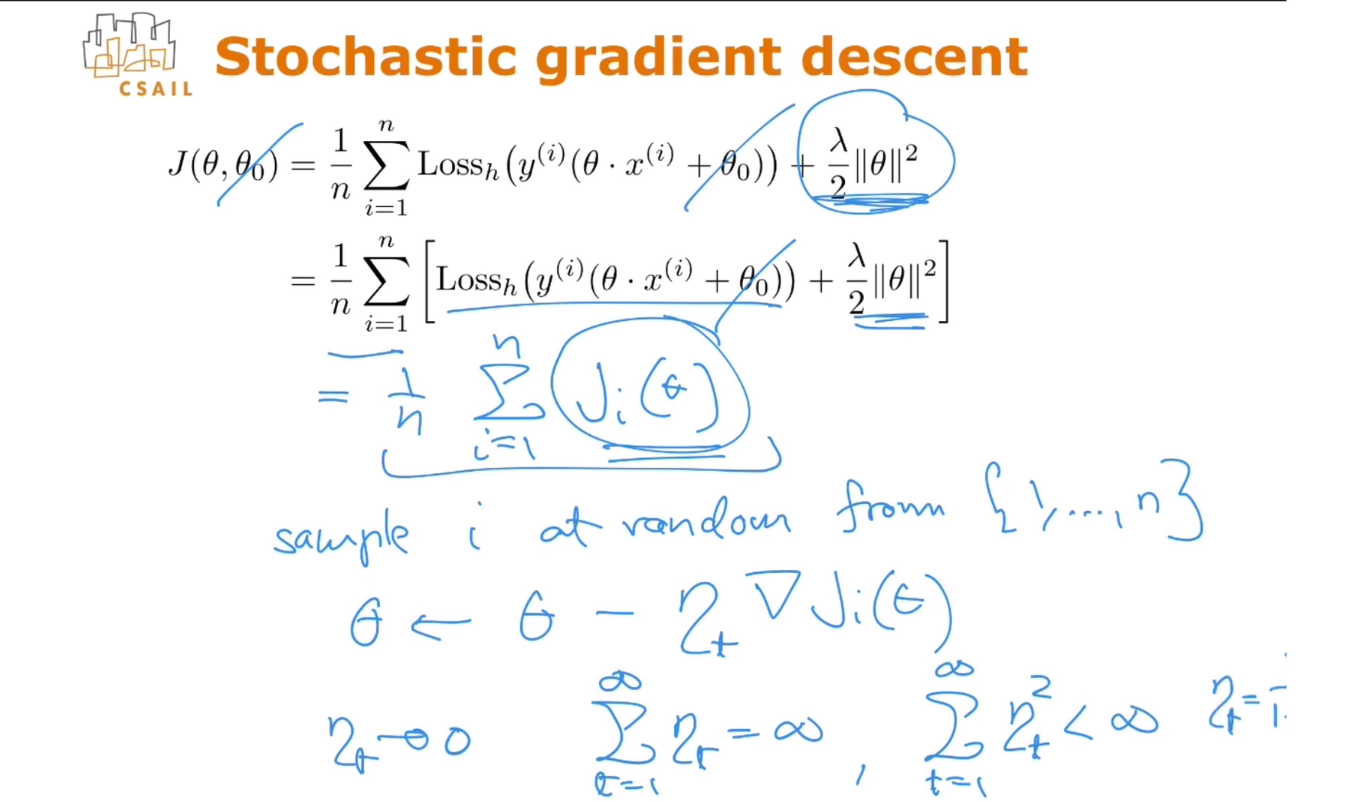




The new learning rate $\eta$ needs to:

- Be lower than the one we would employ for the deterministic gradient descent algorithm in order to reduce the variance from the stochasticity that we're introducing:
  - reduce at each update $t$ with the limit as the steps go to infinite to go to zero $\lim_{t \to \infty} \eta_t = 0$
  - be such that are "square summable", i.e. the sum of the square values must be finite, $\sum_{t=1}^∞ \eta_t^2 < \infty$
- But at the same time retain enough weight that we can reach the minimum wherever it is:
  - if we sum at the infinite the learning rates we must be able to reach infinity, i.e. $\sum_{t=1}^\infty \eta_t = \infty$

One **possible learning rate that satisfies all the above constraints is $\eta_t = \frac{1}{1+t}$.**



Which is the gradient of the objective function with respect to data pair $i$ ?

$\nabla{J_i(\mathbf{\theta})} = \begin{cases}
      0 & \text{when loss=0}\\
      -y^{i}\mathbf{x}^{(i)} & \text{when loss >0}\\
    \end{cases} + \lambda \mathbf{\theta}$

The update rule for the $i$ data pair is hence:

$\mathbf{\theta} = \mathbf{\theta} - \eta_t * \left( \begin{cases}
      0 & \text{when loss=0}\\
      -y^{i}\mathbf{x}^{(i)} & \text{when loss >0}\\
    \end{cases} + \lambda \mathbf{\theta} \right)$



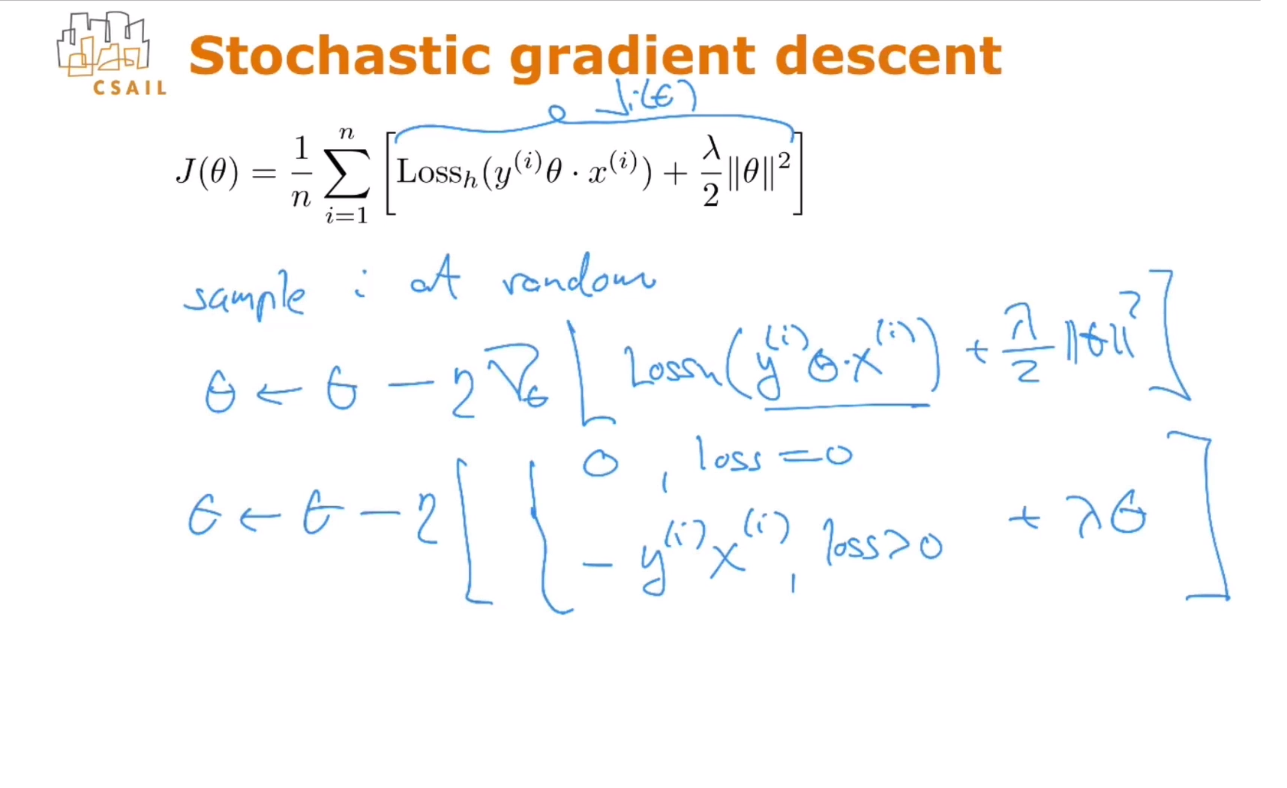


There are **three differences between the update in the stochastic gradient descent method and the update in our earlier perception algorithm** ($\mathbf{\theta} = \mathbf{\theta} + y^{(i)} \mathbf{x}^{(i)}$):

- First, is that we are **actually using a decreasing learning rate due to the stochasticity**.

- The second difference is that we are actually **performing the update, even if we are correctly classifying the example**, because the regularization term will always yield an update, regardless of what the loss is. 

 * And the role of that regularization term is to nudge the parameters a little bit backwards, so **decrease the norm of the parameter vector at every stamp, which corresponds to trying to maximize the margin**.

- To counterbalance that, we will get a non-zero derivative from the last terms, if the loss is non-zero. And that update looks like the perceptor update, but it is actually made even if we correctly classify the example. If the example is within the margin boundaries, you would get a non-zero loss.



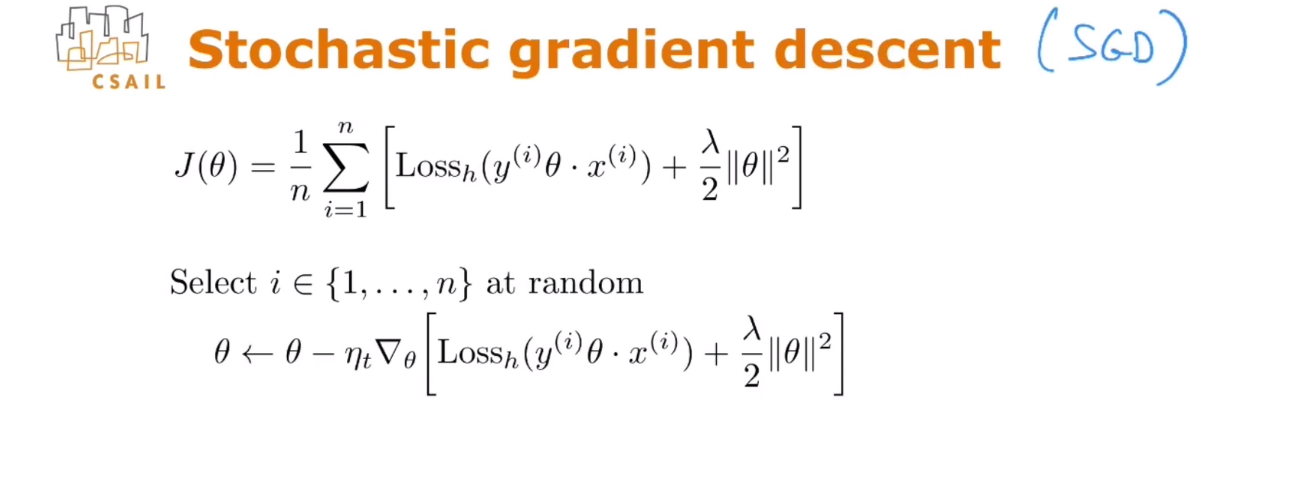


#### **An other point of view on SGD compared to a deterministic approach**

The original concern for using SGD is due to computational constraint: it is inefficient to compute the gradients over all the samples and update the model, think about you have more than a million training samples, and you can only make progress after computing all gradients. Thus, instead of compute the exact value of the gradient over the entire training data set, we randomly sample a fraction of them to estimate the true gradient. You see, there is a trade-off controlled by the batch size (number of samples used in each SGD updates), large batch size is more accurate but slower, and it need to be tuned in practice.

Nowadays, researchers start to understand SGD from a different perspective. The noise caused by SGD could make the trained more robust, (high level idea, noisy updates will make you converge to a flatter minima), which results in a better generalization performance. Thus, SGD could also be viewed as a way of regularization, in that sense, we may say it is better compared to gradient descent.

## **Que : SGD and Hinge Loss**


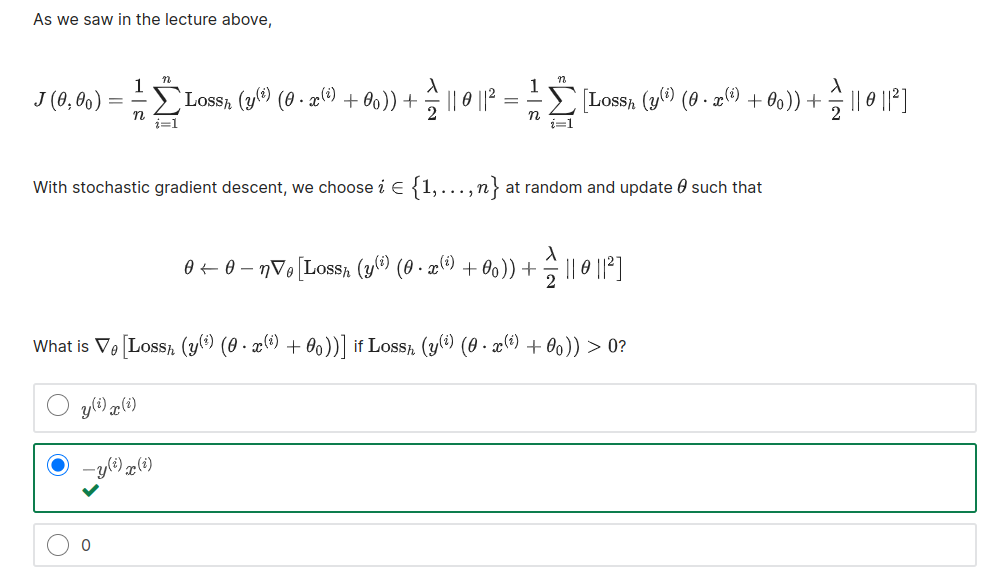

* So if we want all the training samples to have 0 hinge loss, they would have to have the agreement greater or equal to 1.

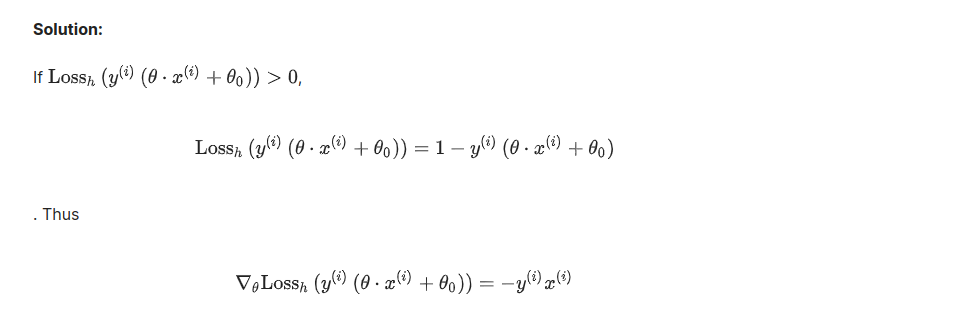

## **Que : Comparison with Perceptron**


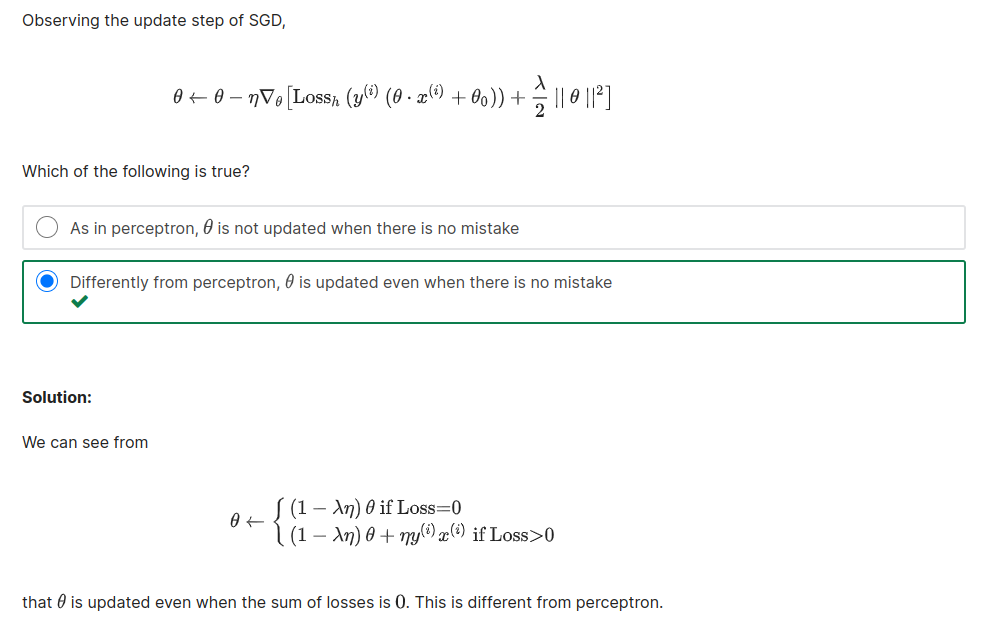


# **4.6. Quadratic program**

Let's consider a simple case where :

(a) The problem is separable and 

(b) We do not allow any error, i.e. 

We want the **loss part of the objective function to be zero** (that's the meaning of "realisable case": we set as constraint that the loss function must return zero).

The problem becomes:

\begin{align}
\min_{(\mathbf{\theta}, \theta_0)} \frac{1}{2}||\mathbf{\theta}||^2
\end{align}

Subject to:
\begin{align}
y^{(i)} * (\mathbf{\theta} \cdot \mathbf{x}^{(i)} + \theta_0 ) \geq 1 ~~ \forall i = 1,...,n\end{align}



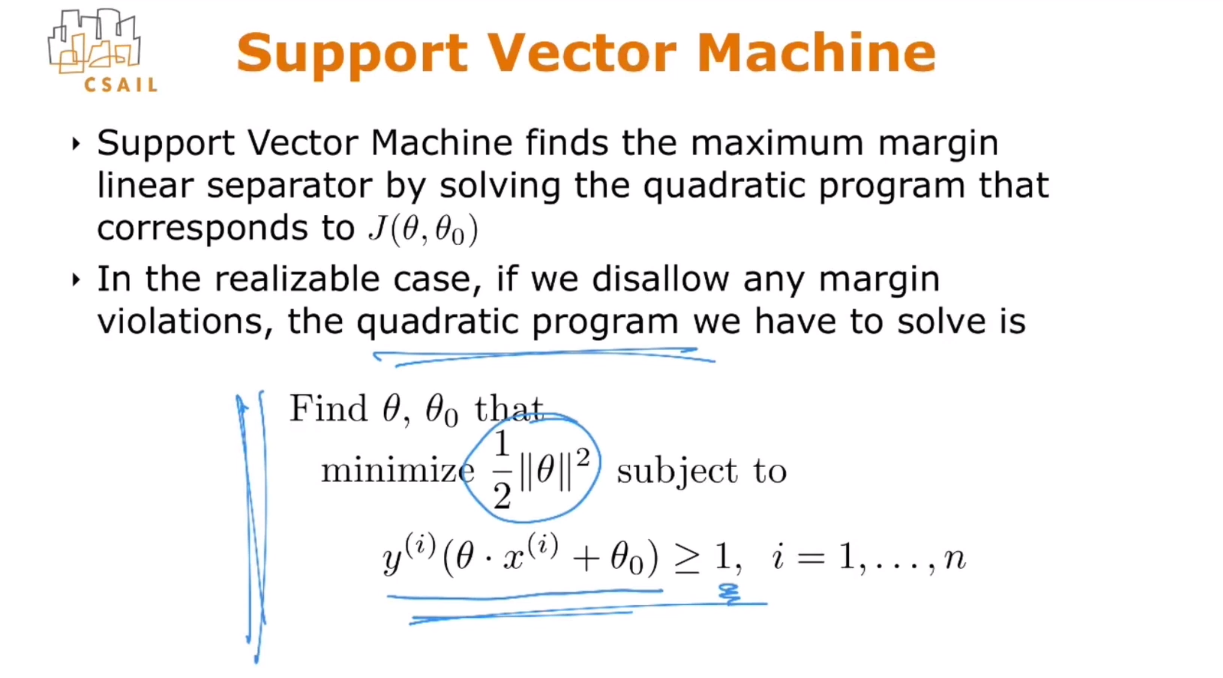


We want hence extend the margins as much as possible while keeping zero losses, that is until the first data pair(s) is reach (we can't go over them otherwise we would start encoring a loss). Note that this is exactly equivalent to the minimisation of our original $J(\theta)$ function when $\lambda$ is very small but not zero. 

* There the zero loss output (in case of a separable problem) is the result of the minimisation of the loss function, here is it imposed as a constraint.

This is a problem quadratic in the objective and with linear constraints, and it can be solved with **so-called quadratic solvers**.

Relaxing the loss constraint and incorporate the loss in the objective would still leave the problem as a quadratic one.

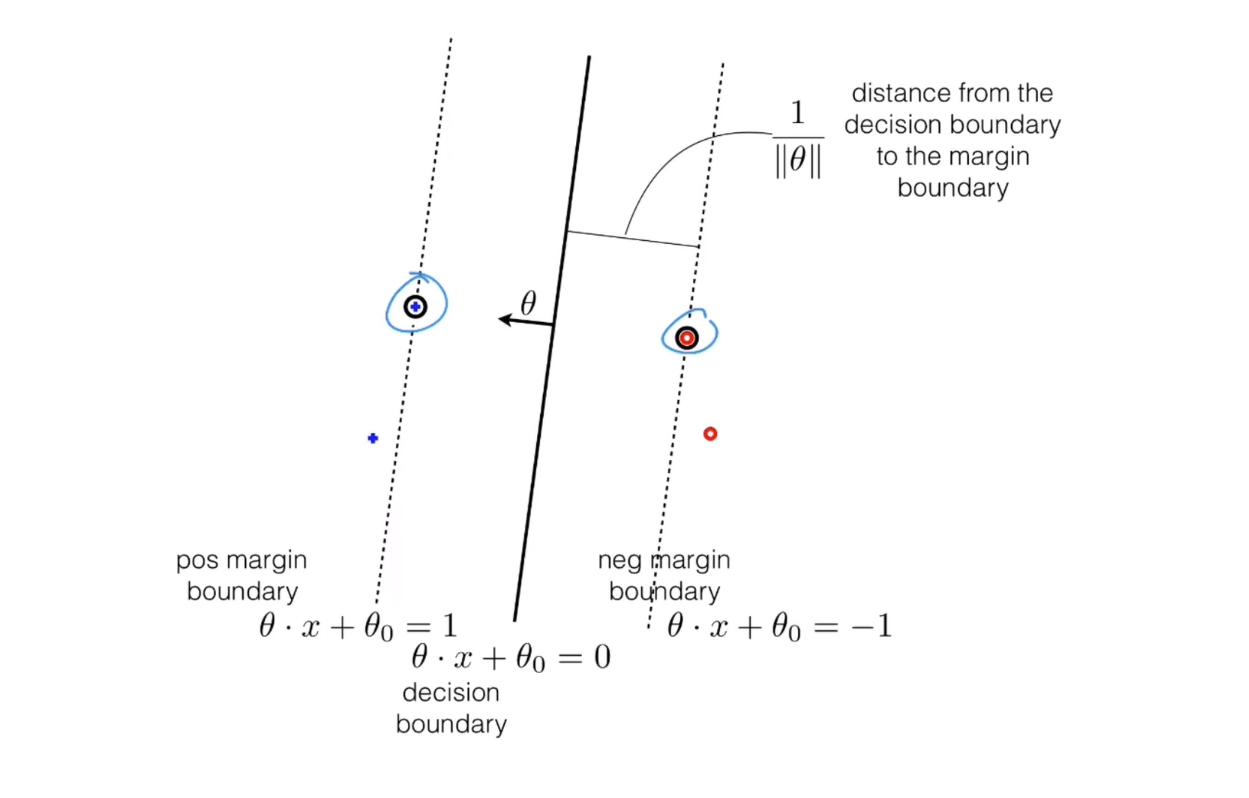


This case is also called **maximum margin separator** or **hard margin SVM** to distinguish it from the **soft margin SVM** we saw earlier where, even in cases of separable problems, we allow to trade some misclassifications for a better regularisation.

**Learning: Support Vector Machines**

* https://www.youtube.com/watch?v=_PwhiWxHK8o&ab_channel=MITOpenCourseWare

## **`Que : The realizable case 1`**


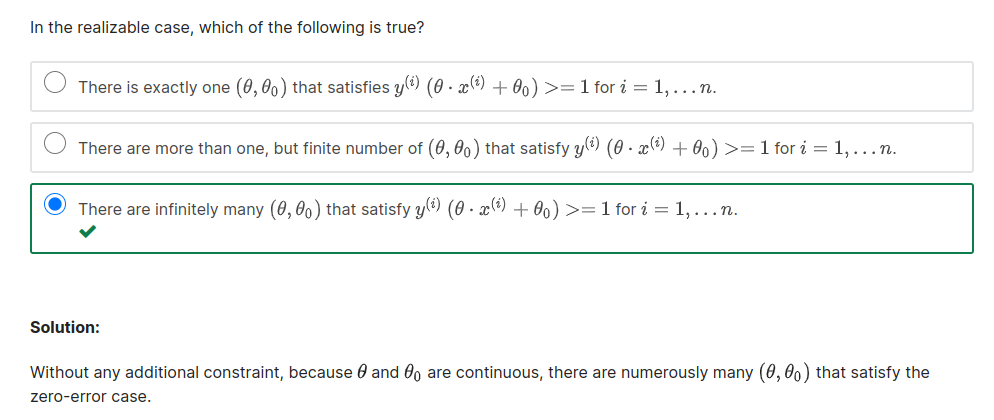

## **`Que : The realizable case 2`**


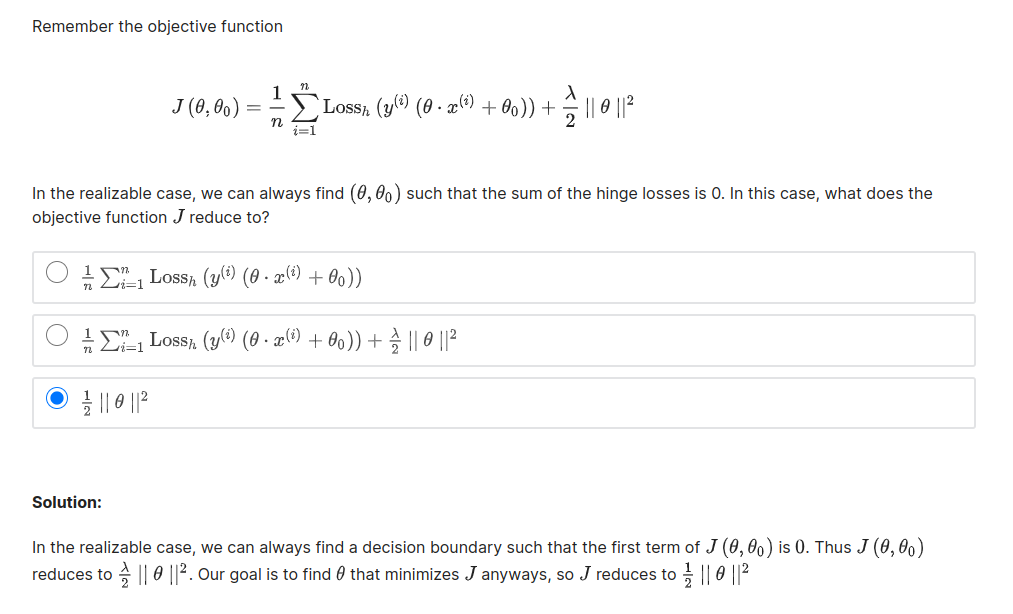

## **`Que : Support Vectors`**


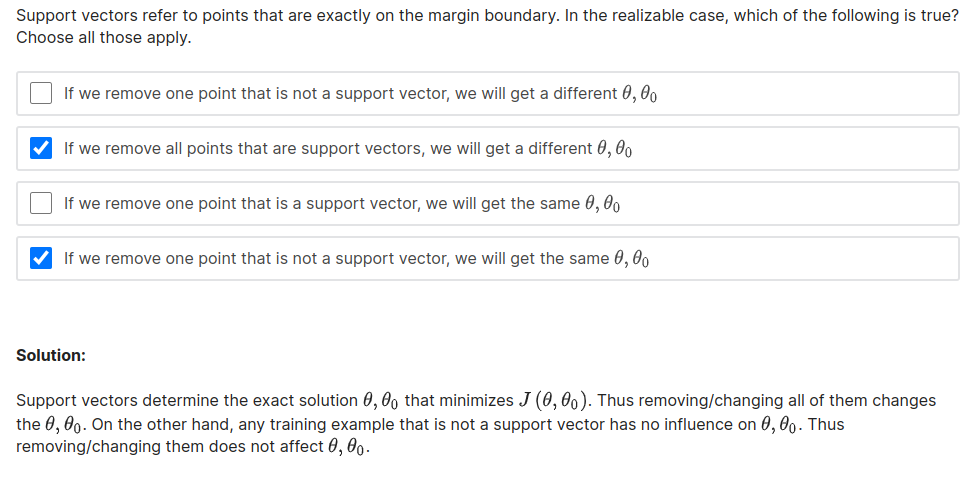

# **Summary**

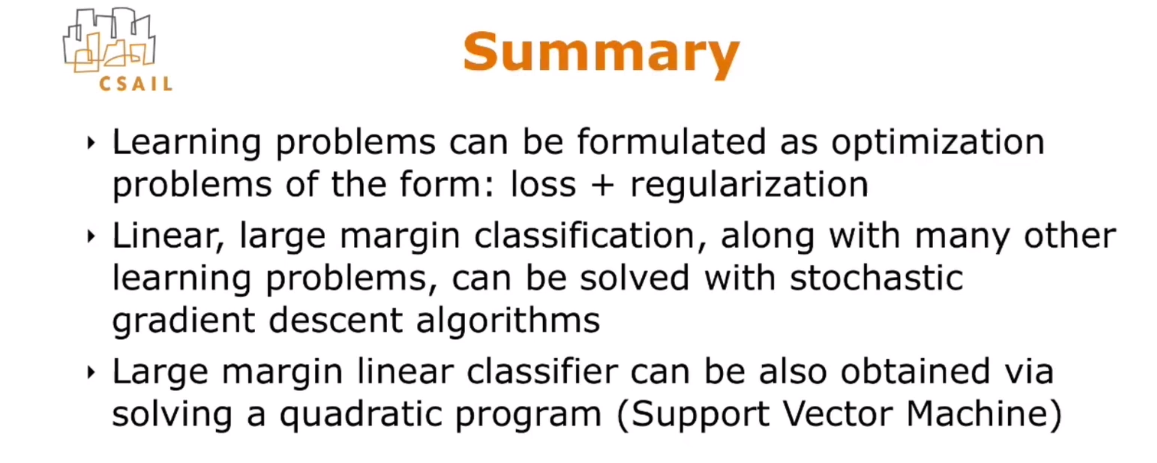